To-Do: 
- add links to all cells with "(>>!!!UPDATE_LINK!!!<<<)"
- improve cells and aesthetics 

# synViser: genome synteny pipeline

This notebook ment to guid you trough genome analysis using synViser. It uses some dummy dataset in `example_data/`
(three species: spA, spB, spC), but feel free to replace it with your data. 

One note: run this notebook from the synViser folder.

## Contents

- [1. Preparation](#1-preparation)
  - [1.1 Packages](#11-packages)
  - [1.2 Preparing inputs](#12-preparing-inputs)
    - [1.2.1 Table of chromosome sizes](#121-table-of-chromosome-sizes)
    - [1.2.2 Links](#122-links)
      - [A. Link files](#a-link-files)
      - [B. OrthoFinder output](#b-orthofinder-output)
- [2. Write a config](#2-write-a-config)
- [3. Draw the plot](#3-draw-the-plot)
  - [3.1 Check the input](#31-check-the-input)
  - [3.2 Customising the plot](#32-customising-the-plot)
- [4. Additional scripts](#4-additional-scripts)
  - [4.1 Dot plot of two chromosomes](#41-dot-plot-of-two-chromosomes)
  - [4.2 Distance between two genes](#42-distance-between-two-genes)
  - [4.3 Chromosome heatmap](#43-chromosome-heatmap)
  - [4.4 Orthologous chromosomes](#44-orthologous-chromosomes)

## 1. Preparation

### 1.1 Packages

synViser needs basic python packages (seaborn is actually needed only for additional visualisation):

In [39]:
!pip install matplotlib pandas numpy seaborn scipy

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


## 1.2 Preparing inputs

synViser needs two things: (1) a table of chromosome sizes and (2) one file of gene pairs
(links) per species.

> If you only have genomes, we have a tool that produces Orthogroups.tsv for all genomes using reference genome query (>>!!!UPDATE_LINK!!!<<<). 
> It maps a reference proteome onto each assembly with miniprot, standardises the annotation with AGAT, and writes the predicted proteins ready for OrthoFinder. 
> Chromosome sizes still come from `samtools faidx`.

### 1.2.1 Table of chr sizes


In order to properly plot chromosomes as bars we need its size. synViser uses one single file with chromosomes from all species. Let's assume you only have `genome.fa`, then in order to get chr_sizes.tsv run `samtools faix`. 

```bash
samtools faidx /path/to/genome_spA.fa
```

You will get `genome_spA.fa.fai`, then parse it with awk to create tab separated `chr_sizes.tsv`. 

First append head: 

```bash
printf "species\tchr\tsize\n" > /path/to/chr_sizes.tsv
```

Then append tab separated chromosome sizes to the file, do it for each species: 

```bash
# species A
awk 'BEGIN{OFS="\t"} {print "spA",$1,$2}' /path/to/genome_spA.fa.fai >> /path/to/chr_sizes.tsv
# species B
awk 'BEGIN{OFS="\t"} {print "spB",$1,$2}' /path/to/genome_spB.fa.fai >> /path/to/chr_sizes.tsv
# species C
awk 'BEGIN{OFS="\t"} {print "spC",$1,$2}' /path/to/genome_spC.fa.fai >> /path/to/chr_sizes.tsv
```

To read this table we will use a function `read_chr_sizes("data")` from `loaders.py`:

In [12]:
from loaders import read_chr_sizes

sizes = read_chr_sizes("example_data/chr_sizes.tsv")
sizes

{'spA': {'A1': 20000000, 'A2': 18000000, 'A3': 16000000, 'A4': 14000000},
 'spB': {'B1': 20000000, 'B2': 34000000, 'B3': 14000000},
 'spC': {'C1': 20000000, 'C2': 18000000, 'C3': 16000000, 'C4': 14000000}}

### 1.2.2 Links 

Second, and probably the most important data we need for plotting, is gene relationship data itself. synViser can take it in two ways:

- A: link files. You already have pairs of orthologous genes/loci
- B: OrthoFinder output. With `Orthogroups.tsv` and a GFF per species synViser builds the pairs itself.

You pick one of the two **in the config**. Everything after this step is identical.

#### A. Link files

One tab separated file per neighbouring pair, six columns, in this order:

```text
chr1  gene1  pos1  chr2  gene2  pos2
```

> Use real gene IDs, and use the same ID for the same gene in both files of a chain, otherwise colours will not continue from spA to spB to spC.

Here we use another function from `loaders.py`,`read_link_path()`. It takes the link file, two species it connects, as well as the `sizes` dictionary we made in 1.2.1:

In [14]:
from loaders import read_link_path

links = read_link_path("example_data/links_spA_spB.tsv", "spA", "spB", sizes)
links.head()

,chr1,gene1,pos1,chr2,gene2,pos2
0,A1,OG0001,627153,B1,OG0001,522225
1,A1,OG0002,878373,B1,OG0002,899757
2,A1,OG0003,1255274,B1,OG0003,1310080
3,A1,OG0004,1641145,B1,OG0004,1687850
4,A1,OG0005,2253882,B1,OG0005,2142012


How many gene pairs each chromosome of spA shares with each chromosome of spB:

In [15]:
import pandas as pd

pd.crosstab(links["chr1"], links["chr2"])

chr2,B1,B2,B3
chr1,,,
A1,70,0,0
A2,0,70,0
A3,0,70,0
A4,0,0,70


#### B. OrthoFinder output

If you ran OrthoFinder you do not need to build link files at all. You need:
- `Orthogroups.tsv` (usually in `OrthoFinder/Results_*/Orthogroups/Orthogroups.tsv`)
- one GFF per species, I mainly tested NCBI or miniprot style GFFs

synViser reads the orthogroup table, finds each gene in the GFF and takes the midpoint of its CDS span as the position and links every gene in species A to every gene of the same orthogroup in species B.

Two things have to match:
1. **Column names.** OrthoFinder names the columns after your input fasta files, e.g. `spA_proteins`. They must be exactly the species names you put in `chain`.
2. **Gene IDs.** The IDs in `Orthogroups.tsv` must be the IDs in the GFF: NCBI GFFs are read from `protein_id=`, miniprot GFFs from `Parent=`.

In [ ]:
orthogroups = pd.read_csv("example_data/orthogroups_demo.tsv", sep = "\t")

orthogroups.head()

,Orthogroup,spA,spB,spC
0,OG0001,spA_g0001,spB_g0001,spC_g0001
1,OG0002,spA_g0002,spB_g0002,spC_g0002
2,OG0003,spA_g0003,spB_g0003,spC_g0003
3,OG0004,spA_g0004,spB_g0004,spC_g0004
4,OG0005,spA_g0005,spB_g0005,spC_g0005


```bash
cat example_data/gff_spA.gff | head
```

In [42]:
from orthofinder import read_orthogroups, read_gff_positions

gene_og = read_orthogroups("example_data/orthogroups_demo.tsv")
positions, gff_sizes = read_gff_positions("example_data/gff_spA.gff")



print(len(gene_og["spA"]), "genes in orthogroups")
print(len(positions), "genes located in the GFF")
print(gff_sizes)

280 genes in orthogroups
280 genes located in the GFF
{'A1': 20000000, 'A2': 18000000, 'A3': 16000000, 'A4': 14000000}


## 3. Write a config

For each figure you would want to make you have to create a separate `.toml` config. 

Few more relevant terms:
- `chain` is sequence you want species chromosomes to appear from top to bottom.  
- `focal` is species whose chromosome colours are followed through the others.

One note on config itsef: all plain `key = value` lines must come before the `[links]` block.

A: if you have `links.tsv`:

In [ ]:
config = """
chr_sizes = "example_data/chr_sizes.tsv"
chain = ["spA", "spB", "spC"]
focal = "spA"

sort = "synteny"
chr_label = true
chr_label_style = "name"

out = "test_plot.png"
dpi = 150

[links]
spA_spB = "example_data/links_spA_spB.tsv"
spB_spC = "example_data/links_spB_spC.tsv"
"""

open("test_config.toml", "w").write(config)

272

B: if you have OrthoFinder output:

In [8]:
config = """
orthogroups = "example_data/orthogroups_demo.tsv"
chain = ["spA", "spB", "spC"]
focal = "spA"
max_copies = 1

sort = "synteny"
chr_label = true
chr_label_style = "name"

out = "test_plot_orthofinder.png"
dpi = 150

[gff]
spA = "example_data/gff_spA.gff"
spB = "example_data/gff_spB.gff"
spC = "example_data/gff_spC.gff"
"""

open("test_config_orthofinder.toml", "w").write(config)

321

## 3. Draw the plot

In [ ]:
from functions import plot
from IPython.display import Image

plot("test_config.toml")
Image("test_plot.png")

### 3.1 Check the input

Check what was loaded:

In [10]:
print("species:", list(sizes))
print()
print("spA:", list(sizes["spA"]))
print("spB:", list(sizes["spB"]))
print("spC:", list(sizes["spC"]))
print()
print("gene pairs spA-spB:", len(links))
print("first pair:", links["gene1"].iloc[0], "-", links["gene2"].iloc[0])

NameError: name 'sizes' is not defined

Species and chromosome names must match between the config and input files.

Check the number of gene pairs too. Too low count usually mean that IDs do not match.

### 3.2 Customising the plot

Plot appearance is set in  the same config.

Detailed config options are described here: (>>!!!UPDATE_LINK!!!<<<)

## 5. Additional analysis scripts

synViser comes with a few small scripts that you run from the command line. They read the
same config you already wrote, so there is nothing new to prepare. 

### 4.1 Dot plot of two chromosomes

Each dot is an orthologous gene pair. Spearman correlation gives a rough measure of collinearity.

Give the two species in the order they appear in `chain`.

  spA-spB: 280 links
  spB-spC: 310 links
saved dotplot_A1_B1.png  (70 orthologs, colinearity +1.00)


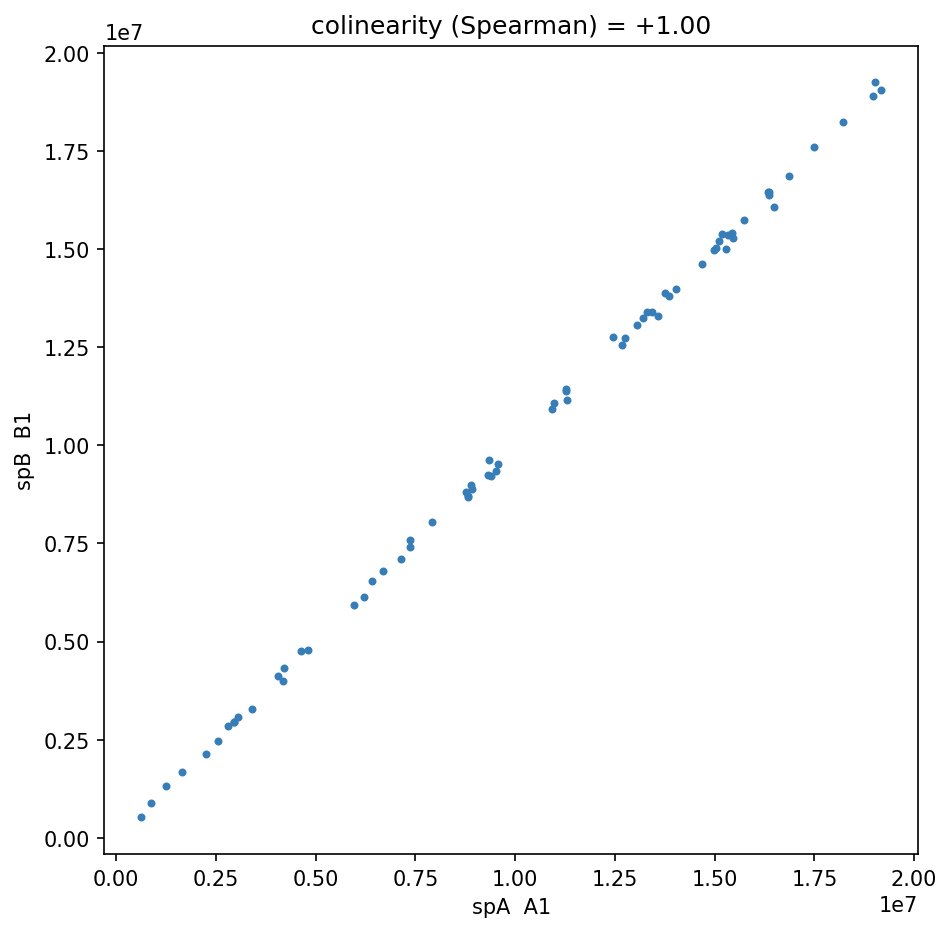

In [44]:
!python dotplot.py my_config.toml spA spB A1 B1 dotplot_A1_B1.png

Image("dotplot_A1_B1.png")

### 4.2 Distance between two genes

Shows whether two gene IDs are present in each species and  whether they share a chromosome and  their distance. 

For link files use IDs from `gene1` or `gene2`. For OrthoFinder, use orthogroup IDs.

  spA-spB: 280 links
  spB-spC: 310 links
species                   chr OG0001          chr OG0050   distance (Mb)
spA                               A1                  A1           13.41
spB                               B1                  B1           13.47
spC                               C1                  C1           13.66
saved gene_distance_demo.png


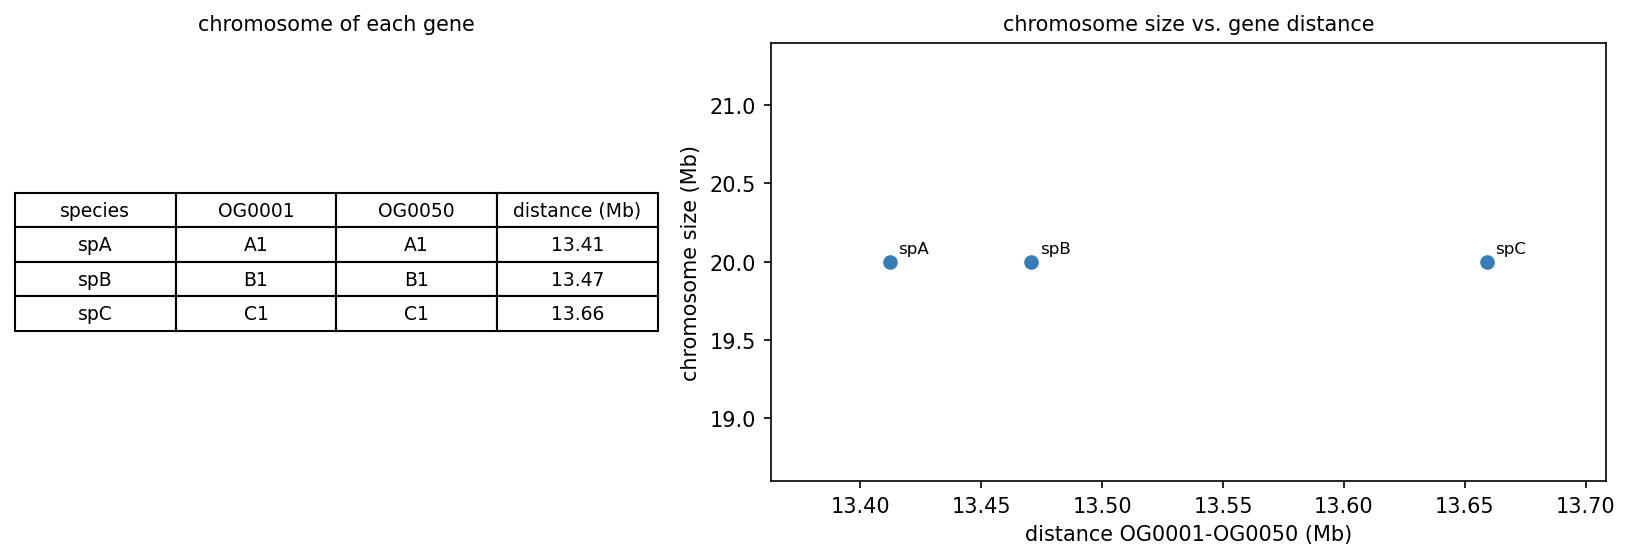

In [49]:
!python gene_distance.py test_config.toml OG0001 OG0050 gene_distance_demo.png

Image("gene_distance_demo.png")

### 4.3 Chromosome heatmap

Counts  the gene pairs for every chromosome pair and clusters on the both axes. Input is one link file.

saved heatmap.png


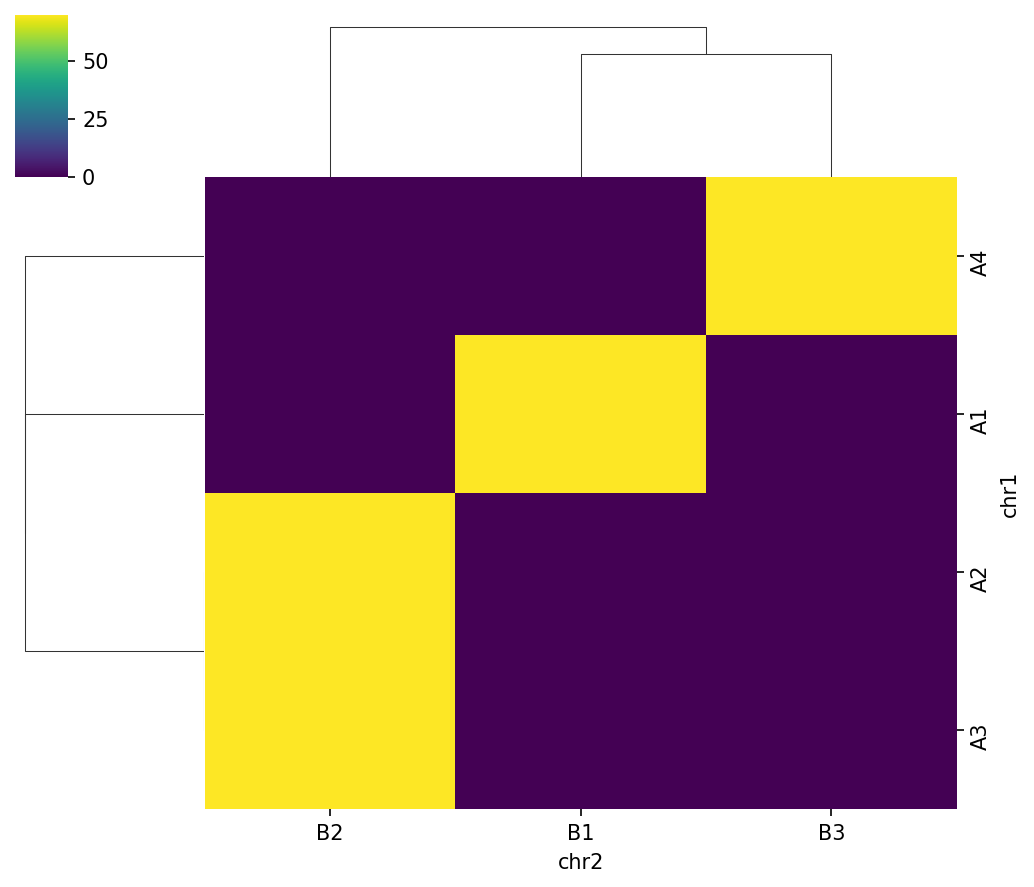

In [40]:
!python ortho_heatmap.py example_data/links_spA_spB.tsv heatmap.png

Image("heatmap.png")

### 4.4 Orthologous chromosomes

Compares every species with the focal  species using  Orthofinder input. Colour shows Jaccard similarity. A red circle marks the largest shared orthogroup count in each row.

Ties get more than one circle. `spB:B2` gets two because it combines `A2` and `A3`.

saved orthologous_chromosomes.png


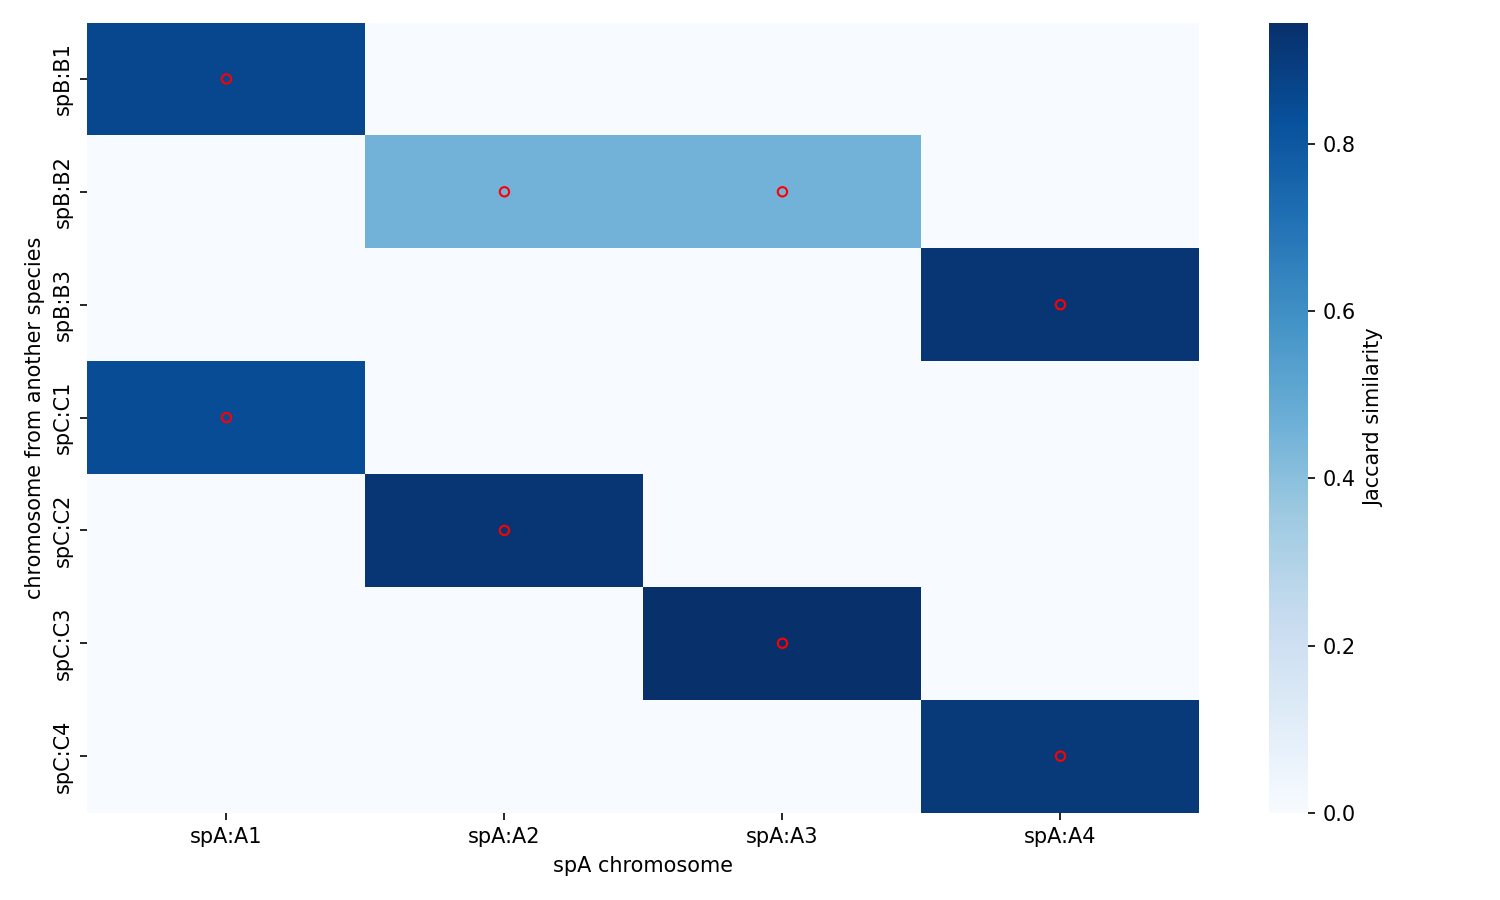

In [41]:
!python chromosome_orthologs.py my_config_orthofinder.toml orthologous_chromosomes.png

Image("orthologous_chromosomes.png")